### Imports

In this section, we import all the libraries required to:
- create and interact with the RL environment,
- define and train a neural network agent,
- store and sample experience during training,
- visualize both results and the explanation graphs generated with pgeon.

In [2]:
# The library of gymnasium
import gymnasium as gym

import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import namedtuple, deque
from itertools import count
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np

# For visualizing the PG
import networkx as nx

# For saving trainings and models
import dill

# To ensure reproducibility of results
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

import warnings
warnings.filterwarnings("ignore")

# Using device GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


#### Importing and Creating Discretizer

In order to use pgeon, we need to transform the continuous state space of the environment into a discrete and interpretable representation.

The LunarLander environment provides observations as continuous values (position, velocity, angle, etc.), which are difficult to interpret directly.
The semantic discretizer converts these values into high-level symbolic predicates, such as:
- lander is on the left
- descending too fast
- tilted to the right
- both legs in contact

Without this step, pgeon would not be able to generate meaningful explanations, since it relies on symbolic representations rather than raw numerical states.

In [3]:
from discretizer import LunarLanderSemanticDiscretizer
from discretizer import Contact, XPos, YPos, YVel, XVel, AngularVel, Angle

discretizer = LunarLanderSemanticDiscretizer()

### Creating Environment and Action Mapping

A mapping of the possible actions inside this LunarLander environment is:
- 0: do nothing
- 1: fire left orientation engine
- 2: fire main engine
- 3: fire right orientation engine

This mapping is not required for training, but it is very useful for interpretability and visualization.
When we later build the policy graph (PG), actions will be displayed using these human-readable labels instead of numeric IDs.


`n_observations` corresponds to the size of the state vector returned by the environment. `n_actions` is how many actions there are in the environment.

In [4]:
# The continuous parameter to false makes the action being discretized as I map them
env = gym.make('LunarLander-v3', continuous=False, gravity=-10.0,
               enable_wind=False, wind_power=15.0, turbulence_power=1.5)

# Mapping of the actions
action_names = {
    0: "Do nothing",
    1: "Left engine",
    2: "Main engine",
    3: "Right engine"
}

n_observations = env.observation_space.shape[0]
n_actions = env.action_space.n

### DQN Agent

#### Agent Imports, defining Transition and Memory replay

We use two neural networks:
- Policy network: the model being actively trained
- Target network: a stable copy used to compute target Q-values

This separation improves training stability by reducing feedback loops in value estimation.

A `Transition` represents a single step of experience collected by the agent.
It stores the full interaction tuple needed for learning.

`ReplayMemory` stores past experiences so the agent can learn from randomized batches instead of sequential data.
This breaks correlation between consecutive transitions and improves learning stability.

We use `AdamW` optimizer, which is well-suited for stabilizing deep Q-learning updates.

In [5]:
from dqn import DQN
policy_net = DQN(n_observations, n_actions).to(device)
target_net = DQN(n_observations, n_actions).to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

Transition = namedtuple("Transition", ["state", "action", "next_state", "reward", "done"])

class ReplayMemory:
    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

memory = ReplayMemory(100000)

# This is the policy_net of the agent
optimizer = optim.AdamW(policy_net.parameters(), lr=1e-4)

#### Model training

We define hyperparameters controlling exploration and learning stability:
- EPSILON: exploration rate (epsilon-greedy strategy)
- EPSILON_DECAY: how fast exploration decreases
- GAMMA: discount factor for future rewards
- TAU: soft update rate for target network
- batch_size: number of experiences per training step

These parameters control the trade-off between exploration and exploitation.

In [30]:
# Training metrics variables
dqn_rewards = []
dqn_lengths = []
dqn_losses = []

# Epsilon-Greedy parameters
EPSILON = 1.0
EPSILON_DECAY = 0.995
EPSILON_MIN = 0.01
GAMMA = 0.99
TAU = 0.005
batch_size = 128
num_episodes = 1500

for episode in tqdm(range(num_episodes)):
    state, info = env.reset()
    state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
    total_reward = 0

    for t in count():
        # Action selector
        if random.random() < EPSILON:
            action = torch.tensor([[env.action_space.sample()]], device=device, dtype=torch.long)
        else:
            with torch.no_grad():
                action = policy_net(state).max(1).indices.view(1, 1)

        next_state_raw, reward, terminated, truncated, _ = env.step(action.item())
        done = terminated or truncated
        total_reward += reward
        
        reward_t = torch.tensor([reward], device=device)
        next_state = torch.tensor(next_state_raw, dtype=torch.float32, device=device).unsqueeze(0)

        # Save in memory
        memory.push(state, action, next_state, reward_t, done)
        state = next_state

        # Optimization
        if len(memory) >= batch_size:
            transitions = memory.sample(batch_size)
            batch = Transition(*zip(*transitions))

            state_batch = torch.cat(batch.state)
            action_batch = torch.cat(batch.action)
            reward_batch = torch.cat(batch.reward)
            next_state_batch = torch.cat(batch.next_state)
            done_batch = torch.tensor(batch.done, device=device, dtype=torch.float32)

            # Currently Q value calculation
            state_action_values = policy_net(state_batch).gather(1, action_batch)

            # Target Q value calculation
            with torch.no_grad():
                next_state_values = target_net(next_state_batch).max(1)[0]
                expected_q = (next_state_values * GAMMA * (1 - done_batch)) + reward_batch

            # Huber lost
            loss = nn.SmoothL1Loss()(state_action_values, expected_q.unsqueeze(1))
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_value_(policy_net.parameters(), 100)
            optimizer.step()
            
            dqn_losses.append(loss.item())

        # Soft Update
        for target_param, param in zip(target_net.parameters(), policy_net.parameters()):
            target_param.data.copy_(TAU * param.data + (1.0 - TAU) * target_param.data)

        if done:
            dqn_rewards.append(total_reward)
            dqn_lengths.append(t + 1)
            break

    # Decline of exploration
    EPSILON = max(EPSILON_MIN, EPSILON * EPSILON_DECAY)

print("Entrenamiento finalizado.")

100%|███████████████████████████████████████████████████████████████████| 1500/1500 [20:53<00:00,  1.20it/s]

Entrenamiento finalizado.


#### Saving model

For saving the policy of the DQN agent we can use the next code which save also the information of the rewards obtained, the length of the episodes and the losses during the training.

In [31]:
torch.save({
    "model": policy_net.state_dict(),
    "rewards": dqn_rewards,
    "lengths": dqn_lengths,
    "losses": dqn_losses,
}, "dqn_lunar_lander_example.pth")
print("Model saved to dqn_lunar_lander.pth")

Model saved to dqn_lunar_lander.pth


#### Loading model

We can get all the information save with the code before using the next code.

In [5]:
policy_net = DQN(n_observations, n_actions).to(device)

checkpoint = torch.load("dqn_lunar_lander_example.pth", weights_only=False)

policy_net.load_state_dict(checkpoint["model"])
dqn_rewards = checkpoint["rewards"]
dqn_lengths = checkpoint["lengths"]
dqn_losses = checkpoint["losses"]

print("Model loaded successfully!")

Model loaded successfully!


#### Plots of the model training

The next code allows us to see the evolution of the rewards, length and losses obtained during the training.

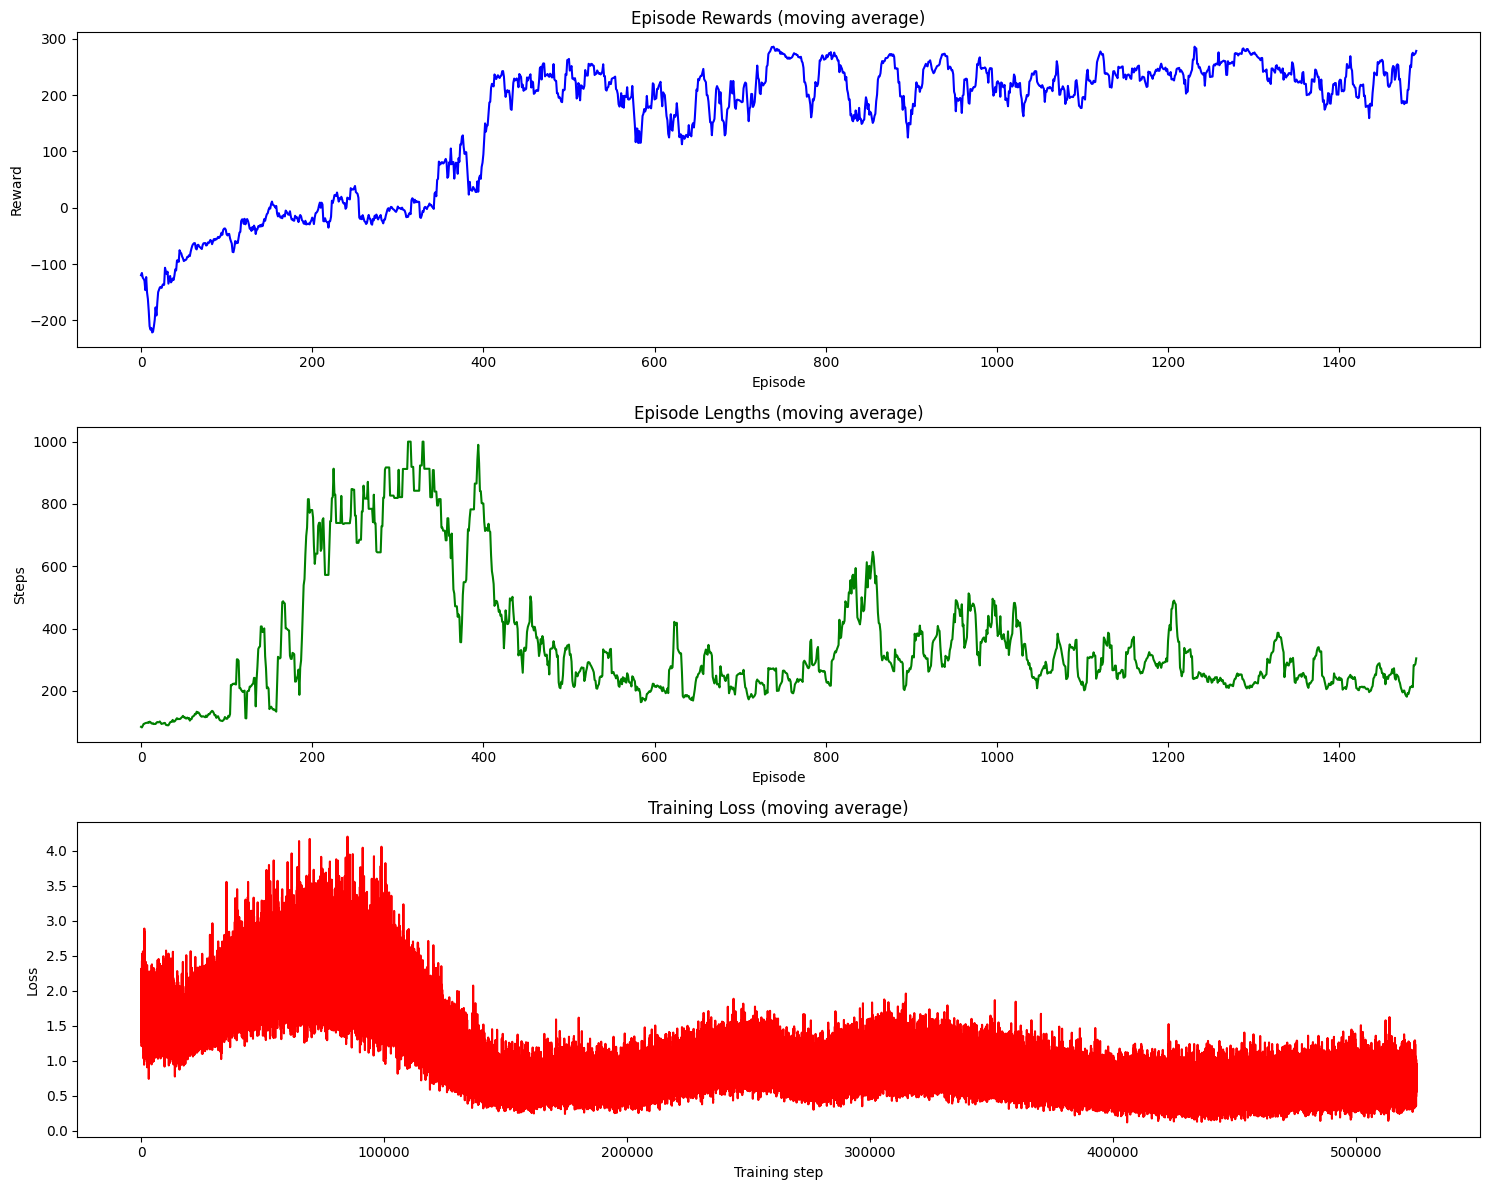

In [6]:
rolling_length = 10

fig, axs = plt.subplots(ncols=1, nrows=3, figsize=(15, 12))

# Rewards
reward_ma = np.convolve(
    np.array(dqn_rewards),
    np.ones(rolling_length),
    mode="valid"
) / rolling_length

axs[0].plot(reward_ma, color="blue")
axs[0].set_title("Episode Rewards (moving average)")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Reward")


# Episode lengths
length_ma = np.convolve(
    np.array(dqn_lengths),
    np.ones(rolling_length),
    mode="valid"
) / rolling_length

axs[1].plot(length_ma, color="green")
axs[1].set_title("Episode Lengths (moving average)")
axs[1].set_xlabel("Episode")
axs[1].set_ylabel("Steps")

# Losses
loss_ma = np.convolve(
    np.array(dqn_losses),
    np.ones(rolling_length),
    mode="valid"
) / rolling_length

axs[2].plot(loss_ma, color="red")
axs[2].set_title("Training Loss (moving average)")
axs[2].set_xlabel("Training step")
axs[2].set_ylabel("Loss")

plt.tight_layout()
plt.show()

The training curves show that the DQN agent progressively learns an effective policy for the environment. At the beginning of training, the moving average reward is negative, which indicates that the agent mostly performs random actions and frequently fails to land correctly. As epsilon decreases and the agent starts exploiting the learned Q-values, the average reward increases significantly. Around the middle of the training process, the reward rises above 200, this suggests that the agent has learned a policy capable of solving the environment in many episodes.

The episode length curve provides additional information about the learning process. During the first episodes, the lander probably fails quickly, resulting in short episodes. Later, the episode length increases considerably. This can be interpreted as the agent having learned to keep the landing module operational for longer, although not necessarily to land efficiently. Once the reward improves, the episode length decreases and becomes more stable, indicating that the agent is able to complete the task in fewer steps.

The loss curve is initially high and unstable, which is expected in DQN because the network is still learning approximate Q-values from highly variable experiences. As training progresses, the loss decreases and stabilizes in a lower range. The loss does not need to converge to zero, since the target values in reinforcement learning are non-stationary and depend on the evolving policy and target network. Overall, the combination of increasing rewards, more stable episode lengths, and reduced loss suggests that the training process was successful.

#### Video of the model

Here we can see a video of the agent's behaviour.

In [7]:
# We put render_mode = human to see the agent in a video
test_env = gym.make("LunarLander-v3", render_mode="human",
                     continuous=False, gravity=-10.0,
                     enable_wind=False, wind_power=15.0, turbulence_power=1.5)
state, info = test_env.reset()
done = False
total_test_reward = 0

print("Takeoff...")

while not done:
    state_t = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
    
    with torch.no_grad():
        # We use the better action
        action = policy_net(state_t).max(1).indices.item()
    
    state, reward, terminated, truncated, info = test_env.step(action)
    total_test_reward += reward
    done = terminated or truncated

print(f"Landing complete. Final reward: {total_test_reward:.2f}")
test_env.close()

Takeoff...
Landing complete. Final reward: 270.33


### Agent Wrapper

In this case I create a wrapper for my DQN agent. It is important because it exposes the trained model thanks to the `act` function. Without it pgeon can not interact with the agent because can't know the agent's behaviour. Instead of this codde you can use the once in the next section because it is the implementation inside the *pgeon* library.

In [35]:
class DQNAgentWrapper:
    def __init__(self, model, device, epsilon=0.05):
        self.model = model
        self.device = device
        self.epsilon = epsilon

    def act(self, observation):
        # exploration
        if np.random.random() < self.epsilon:
            return np.random.randint(4)

        state_t = torch.tensor(
            observation, dtype=torch.float32, device=self.device
        ).unsqueeze(0)

        with torch.no_grad():
            return self.model(state_t).argmax(dim=1).item()

In [36]:
agent = DQNAgentWrapper(policy_net, device)

### Converting the Policy in an Agent

This part is important because transforms a raw neural network into a structured decision policy, separating the learning component from the actual action-selection logic. This step ensures that the resulting object is wrapped into a proper *pgeon* agent interface.

In [5]:
from pgeon.agent import TorchPolicy

policy = TorchPolicy(policy_net, device)

In [6]:
from pgeon.agent import CallableAgent

agent = CallableAgent(policy)

### Approximator of the Agent

To build the agent’s policy approximator, we first import two key classes from `pgeon`. `PolicyApproximatorFromBasicObservation` is responsible for constructing an approximation of the agent’s policy from direct interaction with the environment. Instead of using the internal parameters of the DQN, this class observes the behaviour of the already trained agent by running episodes in the environment. During each episode, the continuous observations produced by LunarLander are transformed into discrete predicate-based states using the discretizer. The resulting trajectories have the form:

state → action → next state → action → next state ...

These trajectories are then used to populate the policy representation. Each observed discrete state is added as a node in the Policy Graph, and each observed transition between two states through a given action is added as an edge. The frequency of states and transitions is also stored, allowing the approximator to later estimate probabilities for actions and transitions.

`GraphRepresentation` defines how this information is stored as a graph. In this representation, nodes correspond to predicate-based states, while edges represent transitions observed when the agent performs an action. Therefore, the Policy Graph provides an interpretable abstraction of the agent’s behaviour: it does not explain the neural network directly, but it summarizes what the trained agent tends to do in the discretized environment.

In this notebook, these two components are combined to create a Policy Graph from the trained DQN agent. The approximator runs the agent in the LunarLander environment, discretizes each observation, records the actions selected by the agent, and builds a graph-based representation of the observed policy.

In [12]:
from pgeon import PolicyApproximatorFromBasicObservation, GraphRepresentation

# Creating the representation
representation = GraphRepresentation()

# Initializing the approximator
approximator = PolicyApproximatorFromBasicObservation(
    discretizer, 
    representation, 
    env, 
    agent
)

#### Fit 500

In this cell, the trained DQN policy is mapped into a `pgeon` Policy Graph. The method `fit(n_episodes=500)` runs the agent for 500 episodes, observes its decisions, discretizes the visited observations, and stores the resulting states and transitions in the graph representation. After the fitting process, the number of discovered states is printed to show how many different predicate-based states were observed during the mapping process.

In [13]:
# Auto mapping of 500 episodes
print("Initiating mapping of the DQN policy to pgeon...")
approximator.fit(n_episodes=500)

print(f"¡Mapping completed!")
print(f"Discovered states: {len(list(approximator.policy_representation.states))}")

Initiating mapping of the DQN policy to pgeon...


Fitting policy approximator...: 100%|█████████████████████████████████████| 500/500 [00:50<00:00,  9.90it/s]

¡Mapping completed!
Discovered states: 5


#### Save Fit

The approximation can be saved using the following code. Later in this notebook, I explain how to export it in both `CSV` and `GRAM` formats.

In [14]:
with open("./dqn_pgeon_fit_500_example.dill", "wb") as f:
    dill.dump(approximator, f)

print("¡DQN approximator saved successfully!")

¡DQN approximator saved successfully!


#### Load Fit

You can load the saved approximator with the next code.

In [11]:
with open("./dqn_pgeon_fit_500_example.dill", "rb") as f:
    approximator_loaded = dill.load(f)

print("¡DQN approximator loaded successfully!")

¡DQN approximator loaded successfully!


### Generating PG from Approximator

This cell retrieves the Policy Graph stored inside the loaded approximator and prints its size. The variable `pg` contains the policy representation generated during the fitting process. Its states correspond to the predicate-based abstractions discovered from the LunarLander observations, while its transitions represent the observed state-action-state relations followed by the trained agent.

In [12]:
pg = approximator_loaded.policy_representation
print(f'Number of states in the PG: {len(list(pg.states))}')
print(f'Number of transitions in the PG: {len(list(pg.transitions))}')

Number of states in the PG: 5
Number of transitions in the PG: 37


The loaded Policy Graph contains 5 states and 37 transitions. This means that, after applying the discretizer, the behaviour observed from the agent was summarized into 5 different symbolic states connected by 37 observed transitions. The small number of states is a consequence of the abstraction process: several continuous LunarLander observations can be mapped to the same predicate-based state.

#### Visualizing States

This cell prints all the states discovered in the Policy Graph. Each state is a predicate-based abstraction of a continuous LunarLander observation. The index assigned to each state is only used to make the output easier to read.

In [13]:
for i, state in enumerate(pg.states):
    print(f"Estado {i}: {state}")

Estado 0: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
Estado 1: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')]
Estado 2: [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
Estado 3: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
Estado 4: [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]


The discovered states describe stable situations of the lander. In all of them, the lander is centered, upright, has no horizontal movement, and has no angular velocity. The main differences between states are related to the vertical position of the lander and the contact with the ground. Some states represent the lander with no ground contact, while others represent contact with the left leg, the right leg, or both legs.

This result suggests that the Policy Graph mainly captures the final landing phase of the trained agent. The small number of states is a consequence of the discretization process, since many different continuous observations are mapped to the same symbolic state.

#### Visualizing PG

With this code you can generate a representation of the PG generated.

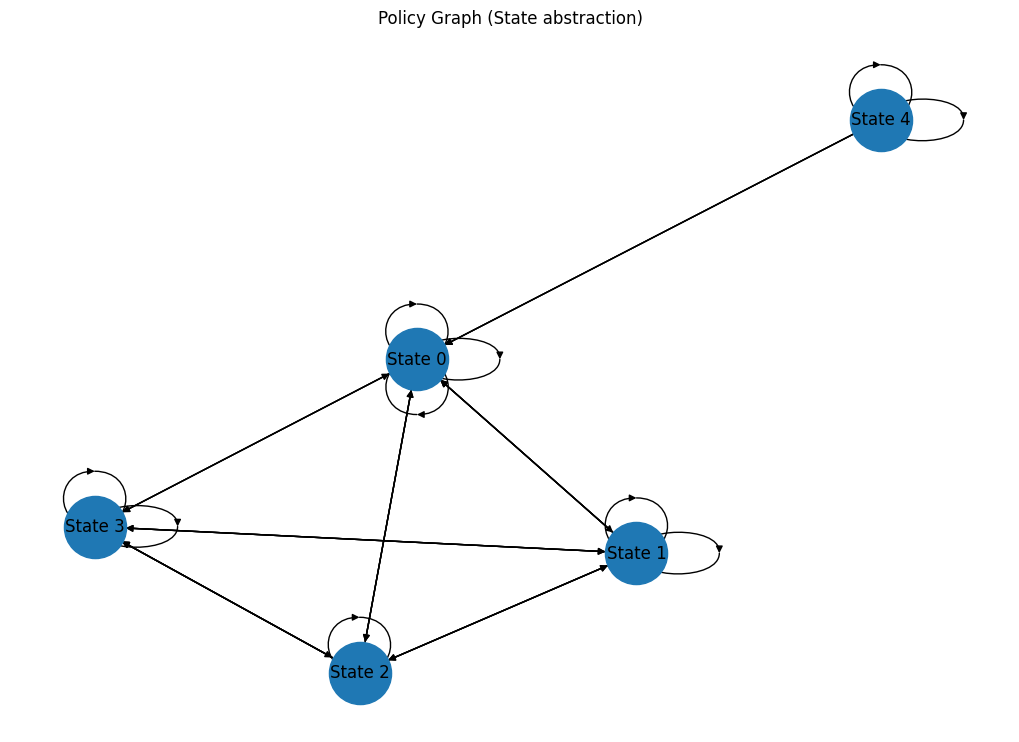

In [14]:
G = pg.graph.backend

mapping = {state: f"State {i}" for i, state in enumerate(G.nodes())}
G_labeled = nx.relabel_nodes(G, mapping)

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G_labeled, seed=42)

nx.draw(
    G_labeled,
    pos,
    with_labels=True,
    node_size=2000,
    arrows=True
)

plt.title("Policy Graph (State abstraction)")
plt.show()

#### P(s) of each State

This next cell prints the states of the Policy Graph together with their associated metadata. For each state, the number of visits indicates how many times the state appeared in the trajectories collected during the fitting process. The value `p(s)` represents the normalized probability of observing that state.

In [15]:
for i, state in enumerate(pg.states):
    data = pg.states[state]

    print(f"Estado {i}: {state}")
    print(f"  Times visited: {data.metadata.frequency}")
    print(f"  p(s):          {data.metadata.probability:.3f}")

Estado 0: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited: 78283
  p(s):          0.509
Estado 1: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')]
  Times visited: 7543
  p(s):          0.049
Estado 2: [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited: 36876
  p(s):          0.240
Estado 3: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited: 4996
  p(s):          0.032
Estado 4: [('XPos', 'CENTE

The most frequent state is `State 0`, with a probability of `0.509`. This state represents the lander centered, upright, stable, and in the descent zone, but without ground contact. `State 2` is also highly frequent, with a probability of `0.240`, and represents the lander with both legs in contact with the ground. This suggests that the agent frequently reaches a stable landing configuration.

`State 4`, with probability `0.170`, corresponds to a stable high-altitude situation before the final descent. `States 1 & 3` have lower probabilities and represent intermediate landing situations where only one leg is touching the ground.

Overall, the state probabilities show that the observed behaviour is concentrated around stable and controlled landing configurations.

#### P(a|s) for each State

This cell analyzes the action distribution associated with each state of the Policy Graph. For every discovered state, the method `question1` is used to answer the question: what actions would the agent take in this state?

The output shows the conditional probability `P(a|s)` for each available action. This probability represents how often the agent selected each action when it was observed in the corresponding symbolic state during the fitting process. The numeric action identifiers are converted into readable action names using the `action_names` dictionary.

This information provides an interpretable view of the approximated policy, since it shows the agent's preferred actions in each predicate-based state.

In [16]:
for i, state in enumerate(pg.states):

    print(f"\nEstado {i}: {state}")
    print("P(a|s):")

    actions_probs = approximator_loaded.question1(state)

    for action, prob in actions_probs:
        print(f"  -> {action_names[action]}: {prob:.3f}")


Estado 0: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
P(a|s):
  -> Right engine: 0.872
  -> Do nothing: 0.041
  -> Right engine: 0.036
  -> Do nothing: 0.031
  -> Left engine: 0.005
  -> Do nothing: 0.005
  -> Right engine: 0.005
  -> Main engine: 0.005

Estado 1: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')]
P(a|s):
  -> Right engine: 0.480
  -> Left engine: 0.220
  -> Left engine: 0.171
  -> Left engine: 0.049
  -> Left engine: 0.049
  -> Main engine: 0.008
  -> Right engine: 0.008
  -> Do nothing: 0.008
  -> Main engine: 0.008

Estado 2: [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'),

Several important patterns can be visualized in this results:
- The policy is strongly biased toward a single dominant action in every states.
- The agent rarely chooses the `do nothing` action.
- Side engines are used much more frequently than the main engine. However, when the rocket has landed as is the case of `state 2`, the most probable action is `main engine`.
- Some action distributions appear asymmetric, which may indicate policy bias or imperfect convergence.

In conclusion, the no-contact descent states, the policy is dominated by lateral engine corrections. In the one-leg contact states, the agent also performs corrective actions, which can be interpreted as attempts to stabilize the landing. Finally, the both-legs contact state is strongly associated with the main engine.

#### P(s', a|s) for each State

This cell prints all the transitions stored in the Policy Graph. Each transition represents an observed relation of the form state-action-next state. For each transition, the output shows the origin state, the action selected by the agent, the destination state, the number of times the transition was observed, and its conditional probability.

The value `p(s_to, a | s_from)` represents the probability of observing both the action and the destination state given the origin state. Therefore, it is more specific than `P(a|s)`, since it also includes the resulting state after executing the action.

In [17]:
for i, transition in enumerate(pg.transitions):
    from_state = transition.from_state
    to_state = transition.to_state
    action = transition.transition.action

    print(f"Transition {i}")
    print(f"From:    {from_state}")
    print(f"Action:  {action_names[action]}")
    print(f"To:      {to_state}")
    print(f"  Times visited:      {transition.transition.frequency}")
    print(f"  p(s_to,a | s_from): {transition.transition.probability:.3f}")
    print()

Transition 0
From:    [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
Action:  Do nothing
To:      [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited:      8
  p(s_to,a | s_from): 0.041

Transition 1
From:    [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
Action:  Left engine
To:      [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited:      1
  p(s_to,a | s_from): 0.005

Transition 2
From:    [('XPos', 'CENT

The most frequent transitions describe the final landing process. From the high-altitude stable state, the agent usually moves into the descent zone. From the no-contact descent state, the dominant transition leads to a one-leg contact state. From the one-leg contact states, the most relevant transitions lead to the both-legs contact state, which represents a stable landing configuration.

Some transitions have very low probabilities and correspond to rare behaviours observed during the approximation process. The self-loop in the both-legs contact state with the main engine should be interpreted carefully, since the discretized state may group together continuous observations that are similar but not exactly equivalent. Overall, the transition probabilities show that the Policy Graph captures meaningful patterns of the trained agent's landing behaviour. The learned landing process can be summarized as:

Hovering --> Single-leg contact --> Both-leg contact --> Stable landed state

### Registering a Desire in the Approximator (First Attempt)

This cell creates a new graph representation prepared for intention-aware analysis. Instead of using the default state metadata, the graph is initialized with `IntentionalStateMetadata`. This type of metadata allows each state to store not only basic information such as frequency and probability, but also information related to desires and inferred intentions.

This step is required before building an Intention Policy Graph, because the intention-aware approximator expects the policy representation to use a metadata class capable of storing intentional information.

In [18]:
from pgeon.desire import IntentionalStateMetadata

representation = GraphRepresentation(
    state_metadata_class=IntentionalStateMetadata
)

This cell creates an `IntentionAwarePolicyApproximator`, which will be used to construct an intention-aware representation of the trained DQN policy. Unlike a basic policy approximator, this class is prepared to work with desires and intentions, allowing the resulting graph to be extended from a Policy Graph into an Intention Policy Graph.

The approximator receives the discretizer, the intention-compatible graph representation, the LunarLander environment, and the trained agent. During the fitting process, it will observe the agent interacting with the environment, discretize the continuous observations into predicate-based states, and store the observed transitions in the graph. Since the graph representation uses `IntentionalStateMetadata`, the resulting states will also be able to store intention-related information as I said before.

In [20]:
from pgeon import IntentionAwarePolicyApproximator

approximator = IntentionAwarePolicyApproximator(
    discretizer=discretizer,
    policy_representation=representation,
    environment=env,
    agent=agent,
    verbose=True
)

#### Fit 500

In [21]:
print("Initiating mapping of the DQN policy to pgeon...")
approximator.fit(n_episodes=500)

print(f"¡Mapping completed!")
print(f"Discovered states: {len(list(approximator.policy_representation.states))}")

Initiating mapping of the DQN policy to pgeon...


Fitting policy approximator...: 100%|█████████████████████████████████████| 500/500 [00:49<00:00, 10.06it/s]

¡Mapping completed!
Discovered states: 5


#### Save Fit

The approximation can be saved using the following code as was done with the PG approximator.

In [22]:
with open("./dqn_pgeon_intention_fit_500_example.dill", "wb") as f:
    dill.dump(approximator, f)

print("¡DQN approximator saved successfully!")

¡DQN approximator saved successfully!


#### Load Fit

You can load the save policy with the next code.

In [23]:
with open("./dqn_pgeon_intention_fit_500_example.dill", "rb") as f:
    approximator = dill.load(f)

print("¡DQN approximator loaded successfully!")

¡DQN approximator loaded successfully!


#### Declaring the desire and registering in the Approximator

Here we define a symbolic goal state using a set of predicates. Each predicate represents a relevant condition of the LunarLander environment. In this case, the goal state requires the lander to be upright, centered, and in contact with the ground with both legs.

This goal state does not describe the full environment state, but only the subset of conditions that are relevant for the desired behaviour. Therefore, it can be used later to define a desire associated with achieving a stable landing configuration.

In [24]:
from pgeon.discretizer import Predicate, PredicateBasedState

goal_state = PredicateBasedState(
    predicates={
        Predicate(Angle.UPRIGHT),
        Predicate(Contact.BOTH_LEGS),
        Predicate(XPos.CENTER_POS)
    }
)

This next cell defines a desire named `rest_after_landing`. The desire is composed with the goal state defined before and an associated action. The associated action is `Action(0)`, which corresponds to `doing nothing`.

Therefore, this desire expresses that, once the lander has reached a stable landing configuration, the expected behaviour is to remain still and avoid activating any engine. This desire will later be used to analyze whether the agent's policy is aligned with this interpretable objective.

In [25]:
from pgeon.desire import Desire
from pgeon.discretizer import Action

rest_after_landing = Desire(
    name="rest_after_landing",
    action=Action(0),
    clause=goal_state
)

Once the desire is created, it is registered in the IPG and it is calculated the statistics of this desire.

In [26]:
approximator.register_desire(rest_after_landing)

#### Computing P(a∊ Ad | s∊Sd)

The method `compute_desire_statistics` identifies all states that satisfy a given desire and returns both the probability of executing the desire-related action in those states and the corresponding state descriptions.

In [27]:
approximator.compute_desire_statistics(rest_after_landing)

([0.003656307129798903],
 [[('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]])

The result shows that only one symbolic state satisfies the clause of the desire. This state corresponds to a stable landing configuration, where the lander is centered, upright, has no horizontal movement, no angular velocity, and both legs are in contact with the ground. However, the probability of executing the desired action in this state is only approximately 0.0036.

This indicates that the learned policy is not aligned with the defined desire. Although the agent reaches the symbolic state associated with a successful landing, it almost never selects the action `Do nothing` in that state. Therefore, the desire analysis reveals a mismatch between an interpretable expected behaviour and the behaviour captured from the trained DQN policy. It is expected that once the agent land correctly it does not move anymore.

#### Computing Id(s)

This cell prints the intention values associated with each state of the graph. For every symbolic state, `get_intentions` returns the desires linked to that state and their corresponding intention value `I_d(s)`.

In [29]:
for s in approximator.get_all_state_ids():
    intentions = approximator.get_intentions(s)
    
    print(f"State: {s}")
    
    for d, I_ds in intentions.items():
        print(f"  Desire: {d.name} -> I_d(s) = {I_ds}")
    
    print()

State: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.08129309914492598

State: [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.06298460108429736

State: [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.10240405880570613

State: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I

In this example, only the desire `rest_after_landing` is evaluated. The highest value appears in the state where the lander has both legs in contact with the ground, which is coherent with the definition of the desire. The one-leg contact states also obtain non-zero values, since they are close to the final landing condition.

However, all intention values are relatively low. This suggests that, although the agent reaches states related to the desired landing configuration, its behaviour is not strongly aligned with the expected action of the desire, which was to do nothing after landing.

### Registering more Desires in the Approximator (Second Attempt)

The new desire, `stable_rocket`, represents a general stability condition. It is satisfied when the lander is upright and has no angular velocity. The associated action is `Do nothing`, meaning that if the rocket is already stable in terms of orientation, the expected behaviour is to avoid unnecessary corrections.

In [30]:
goal_state = PredicateBasedState(
    predicates={
        Predicate(Angle.UPRIGHT),
        Predicate(AngularVel.NO_ROTATION)
    }
)

stable_rocket = Desire(
    name="stable_rocket",
    action=Action(0),
    clause=goal_state
)

In [31]:
approximator.register_desire(stable_rocket)

The other desire, `center_controlled_descending`, represents a more specific controlled descent condition. It requires the lander to be upright, not rotating, horizontally centered, and with a controlled vertical velocity. The associated action is also `Do nothing`, meaning that if the lander is already centered and descending in a stable way, the expected behaviour is to remain inactive.


In [32]:
goal_state = PredicateBasedState(
    predicates={
        Predicate(Angle.UPRIGHT),
        Predicate(AngularVel.NO_ROTATION),
        Predicate(XPos.CENTER_POS),
        Predicate(YVel.HOVERING)
    }
)

center_controlled_descending = Desire(
    name="center_controlled_descending",
    action=Action(0),
    clause=goal_state
)

In [33]:
approximator.register_desire(center_controlled_descending)

#### Computing P(a∊ Ad | s∊Sd)

In [34]:
approximator.compute_desire_statistics(stable_rocket)

([0.09923664122137404,
  0.06451612903225806,
  0.003656307129798903,
  0.008130081300813009,
  0.07692307692307693],
 [[('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HO

In [35]:
approximator.compute_desire_statistics(center_controlled_descending)

([0.09923664122137404,
  0.06451612903225806,
  0.003656307129798903,
  0.008130081300813009,
  0.07692307692307693],
 [[('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HO

The results for `stable_rocket` and `center_controlled_descending` are identical because all states discovered in the Policy Graph satisfy the predicates required by both desires. Although the second desire is more restrictive, every state in the graph is already upright, centered, non-rotating, and classified as hovering.

The returned probabilities correspond to the probability of executing the desired action, `Do nothing`, in each state that satisfies the desire. These probabilities are low in all cases. The highest value is approximately 0.099, while the both-legs contact state has a probability of only approximately 0.0036.

This indicates that, even in states that appear stable according to the symbolic abstraction, the trained agent rarely chooses to remain inactive. Therefore, these desires reveal that the learned policy is not strongly aligned with the expected action `Do nothing`. This may be because the agent has learned to perform constant corrections, or because the discretization groups together continuous situations that still require control actions.

#### Computing Id(s)

In [38]:
for s in approximator.get_all_state_ids():
    intentions = approximator.get_intentions(s)
    
    print(f"State: {s}")
    
    for d, I_ds in intentions.items():
        print(f"  Desire: {d.name} -> I_d(s) = {I_ds}")
    
    print()

State: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.08129309914492598
  Desire: stable_rocket -> I_d(s) = 0.22392419467708874
  Desire: center_controled_descending -> I_d(s) = 0.22392419467708874

State: [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.06298460108429736
  Desire: stable_rocket -> I_d(s) = 0.3143789598250324
  Desire: center_controled_descending -> I_d(s) = 0.3143789598250324

State: [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) =

The intention values show how strongly each state is associated with each defined desire. The desires `stable_rocket` and `center_controlled_descending` obtain exactly the same values in all states because, in the generated Policy Graph, all discovered states satisfy the predicates required by both desires. Although the second desire is more specific, the available graph only contains states that are already upright, centered, non-rotating, and classified as hovering.

The desire `rest_after_landing` obtains lower values in all states. Its highest value appears in the state where both legs are in contact with the ground, which is coherent with the definition of the desire. However, the value is still low, indicating that the agent does not strongly express the expected behaviour of doing nothing after landing.

The highest intention values for `stable_rocket` and `center_controlled_descending` appear in the no-contact states, especially the high-altitude state. This suggests that the trained policy is more strongly associated with maintaining stability during flight than with remaining inactive after landing.

### Trying Saving Policy Representation in CSV and GRAM extension

To avoid having to recreate all the policy representation we can save it in different formats such as CSV or GRAM. In this part we have an example of both options.

In [83]:
with open("./dqn_pgeon_fit_500_example.dill", "rb") as f:
    approximator = dill.load(f)

print("¡DQN approximator loaded successfully!")

¡DQN approximator loaded successfully!


Saving as csv.

#### Saving as CSV

In the case of CSV we need to save the nodes and edges.

In [84]:
from pathlib import Path

approximator.policy_representation.save_csv(
    discretizer=approximator.discretizer,
    nodes_path=Path("policy_nodes.csv"),
    edges_path=Path("policy_edges.csv"),
)

#### Saving as GRAM

In the case of GRAM it is not necessary to save separate node and edge files as in CSV, saving nodes and edges, because it is save the way to create the PG.

In [85]:
approximator.policy_representation.save_gram(
    discretizer=approximator.discretizer,
    path=Path("policy.gram"),
)

#### Loading from CSV

This is the form to load the policy from a CSV and how to recreate the approximator.

In [86]:
loaded_policy = GraphRepresentation.load_csv(
    graph_backend="networkx",
    discretizer=approximator.discretizer,
    nodes_path=Path("policy_nodes.csv"),
    edges_path=Path("policy_edges.csv"),
)

In [87]:
new_approximator = PolicyApproximatorFromBasicObservation(
    agent=agent,
    environment=env,
    discretizer=discretizer,
    policy_representation=loaded_policy,
)

In [88]:
# Auto mapping of 500 episodes
print("Initiating mapping of the DQN policy to pgeon...")
new_approximator.fit(n_episodes=500)

print(f"¡Mapping completed!")
print(f"Discovered states: {len(list(approximator.policy_representation.states))}")

Initiating mapping of the DQN policy to pgeon...


Fitting policy approximator...: 100%|█████████████████████████████████████| 500/500 [00:48<00:00, 10.31it/s]

¡Mapping completed!
Discovered states: 5


In [89]:
pg = new_approximator.policy_representation
print(f'Number of states in the PG: {len(list(pg.states))}')
print(f'Number of transitions in the PG: {len(list(pg.transitions))}')

Number of states in the PG: 5
Number of transitions in the PG: 37


#### Loading from GRAM

And this is the form to load the policy from a GRAM and how to recreate the approximator.

In [90]:
loaded_policy = GraphRepresentation.load_gram(
    graph_backend="networkx",
    discretizer=approximator.discretizer,
    path=Path("policy.gram"),
)

In [91]:
new_approximator = PolicyApproximatorFromBasicObservation(
    agent=agent,
    environment=env,
    discretizer=discretizer,
    policy_representation=loaded_policy,
)

In [92]:
# Auto mapping of 500 episodes
print("Initiating mapping of the DQN policy to pgeon...")
new_approximator.fit(n_episodes=500)

print(f"¡Mapping completed!")
print(f"Discovered states: {len(list(approximator.policy_representation.states))}")

Initiating mapping of the DQN policy to pgeon...


Fitting policy approximator...: 100%|█████████████████████████████████████| 500/500 [00:49<00:00, 10.19it/s]

¡Mapping completed!
Discovered states: 5


In [93]:
pg = new_approximator.policy_representation
print(f'Number of states in the PG: {len(list(pg.states))}')
print(f'Number of transitions in the PG: {len(list(pg.transitions))}')

Number of states in the PG: 5
Number of transitions in the PG: 37


### Trying Saving Approximators in PICKLE extension

We can also save the approximator with the Pickle extension instead of saving the policy.

#### Saving

In [94]:
new_approximator.save("pickle", "./model.pickle")

#### Loading

In [95]:
from pgeon import PolicyApproximatorFromBasicObservation

approximator_loaded = PolicyApproximatorFromBasicObservation.from_pickle("./model.pickle")

In [96]:
# Auto mapping of 500 episodes
print("Initiating mapping of the DQN policy to pgeon...")
approximator_loaded.fit(n_episodes=500)

print(f"¡Mapping completed!")
print(f"Discovered states: {len(list(approximator.policy_representation.states))}")

Initiating mapping of the DQN policy to pgeon...


Fitting policy approximator...: 100%|█████████████████████████████████████| 500/500 [00:50<00:00,  9.98it/s]

¡Mapping completed!
Discovered states: 5


In [97]:
pg = approximator_loaded.policy_representation
print(f'Number of states in the PG: {len(list(pg.states))}')
print(f'Number of transitions in the PG: {len(list(pg.transitions))}')

Number of states in the PG: 5
Number of transitions in the PG: 37


### Trying Saving Intention-aware Policy Representation in CSV and GRAM extension

As we did with the PG, we can also save the IPG in CSV or GRAM extension files.

In [98]:
with open("./dqn_pgeon_intention_fit_500_example.dill", "rb") as f:
    approximator = dill.load(f)

print("¡DQN approximator loaded successfully!")

¡DQN approximator loaded successfully!


#### Saving as CSV

In [99]:
approximator.policy_representation.save_csv(
    discretizer=approximator.discretizer,
    nodes_path=Path("pg_intention_nodes.csv"),
    edges_path=Path("pg_intention_edges.csv"),
)

#### Saving as GRAM

In [100]:
approximator.policy_representation.save_gram(
    discretizer=approximator.discretizer,
    path=Path("pg_intention.gram"),
)

#### Loading from CSV

In [101]:
loaded_policy = GraphRepresentation.load_csv(
    graph_backend="networkx",
    discretizer=approximator.discretizer,
    nodes_path=Path("pg_intention_nodes.csv"),
    edges_path=Path("pg_intention_edges.csv"),
)

loaded_policy.state_metadata_class = IntentionalStateMetadata

In [102]:
new_intention_approximator = IntentionAwarePolicyApproximator(
    agent=agent,
    environment=env,
    discretizer=discretizer,
    policy_representation=loaded_policy,
)

In [103]:
# Auto mapping of 500 episodes
print("Initiating mapping of the DQN policy to pgeon...")
new_intention_approximator.fit(n_episodes=500)

print(f"¡Mapping completed!")
print(f"Discovered states: {len(list(approximator.policy_representation.states))}")

Initiating mapping of the DQN policy to pgeon...


Fitting policy approximator...: 100%|█████████████████████████████████████| 500/500 [00:48<00:00, 10.38it/s]

¡Mapping completed!
Discovered states: 5


In [104]:
pg = new_intention_approximator.policy_representation
print(f'Number of states in the PG: {len(list(pg.states))}')
print(f'Number of transitions in the PG: {len(list(pg.transitions))}')

Number of states in the PG: 5
Number of transitions in the PG: 37


#### Loading from GRAM

In [105]:
loaded_policy = GraphRepresentation.load_gram(
    graph_backend="networkx",
    discretizer=approximator.discretizer,
    path=Path("pg_intention.gram"),
)

loaded_policy.state_metadata_class = IntentionalStateMetadata

In [106]:
new_intention_approximator = IntentionAwarePolicyApproximator(
    agent=agent,
    environment=env,
    discretizer=discretizer,
    policy_representation=loaded_policy,
)

In [107]:
# Auto mapping of 500 episodes
print("Initiating mapping of the DQN policy to pgeon...")
new_intention_approximator.fit(n_episodes=500)

print(f"¡Mapping completed!")
print(f"Discovered states: {len(list(approximator.policy_representation.states))}")

Initiating mapping of the DQN policy to pgeon...


Fitting policy approximator...: 100%|█████████████████████████████████████| 500/500 [00:49<00:00, 10.08it/s]

¡Mapping completed!
Discovered states: 5


In [108]:
pg = new_intention_approximator.policy_representation
print(f'Number of states in the PG: {len(list(pg.states))}')
print(f'Number of transitions in the PG: {len(list(pg.transitions))}')

Number of states in the PG: 5
Number of transitions in the PG: 37


### Trying Saving Intention-aware Policy Approximators in PICKLE extension

And finally it can be save the IPG in pickle extension, in this example we recreate the desire `rest_after_landing` to show that we get the same results.

In [118]:
from pgeon.discretizer import Predicate, PredicateBasedState

goal_state = PredicateBasedState(
    predicates={
        Predicate(Angle.UPRIGHT),
        Predicate(Contact.BOTH_LEGS),
        Predicate(XPos.CENTER_POS)
    }
)

In [119]:
from pgeon.desire import Desire
from pgeon.discretizer import Action

rest_after_landing = Desire(
    name="rest_after_landing",
    action=Action(0),
    clause=goal_state
)

In [120]:
new_intention_approximator.register_desire(rest_after_landing)

#### Saving

In [121]:
new_intention_approximator.save("pickle", "./intention_model.pickle")

#### Loading

In [122]:
from pgeon import IntentionAwarePolicyApproximator

approximator_loaded = IntentionAwarePolicyApproximator.from_pickle("./intention_model.pickle")

In [123]:
approximator_loaded.compute_desire_statistics(rest_after_landing)

([0.003656307129798903],
 [[('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]])

### From PG to IPG

With the next code we create an IPG from a PG without having to use the policy of the agent, just with the PG that we want to transform.

In [6]:
with open("./dqn_pgeon_fit_500_example.dill", "rb") as f:
    approximator_loaded = dill.load(f)

print("¡DQN approximator loaded successfully!")

¡DQN approximator loaded successfully!


In [7]:
pg = approximator_loaded.policy_representation
print(f'Number of states in the PG: {len(list(pg.states))}')
print(f'Number of transitions in the PG: {len(list(pg.transitions))}')

Number of states in the PG: 5
Number of transitions in the PG: 37


The method `from_pg` creates an `IntentionAwarePolicyApproximator` from an already existing Policy Graph. Instead of running the fitting process again, it copies the states, transitions, frequencies, probabilities, and trajectories from the original policy approximator.

The main difference is that the new graph representation uses `IntentionalStateMetadata`. This metadata keeps the original state frequency and probability, but also adds an empty `intention` dictionary. This dictionary will later be used to store the intention values associated with different desires.

In [8]:
from pgeon import IntentionAwarePolicyApproximator

ipg = IntentionAwarePolicyApproximator.from_pg(
    approximator_loaded
)

In [9]:
print(type(ipg))
print(len(list(ipg.policy_representation.states)))

<class 'pgeon.intention_aware_policy_approximator.IntentionAwarePolicyApproximator'>
5


As we can see the `ipg` variable type is a `IntentionAwarePolicyApproximator` and has the same number of states than the declarations done before. We can also see that for the `rest_after_landing` desire we obtain the same results that it is expected.

In [10]:
from pgeon.discretizer import Predicate, PredicateBasedState

goal_state = PredicateBasedState(
    predicates={
        Predicate(Angle.UPRIGHT),
        Predicate(Contact.BOTH_LEGS),
        Predicate(XPos.CENTER_POS)
    }
)

In [11]:
from pgeon.desire import Desire
from pgeon.discretizer import Action

rest_after_landing = Desire(
    name="rest_after_landing",
    action=Action(0),
    clause=goal_state
)

In [12]:
ipg.register_desire(rest_after_landing)

In [13]:
ipg.compute_desire_statistics(rest_after_landing)

([0.003656307129798903],
 [[('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]])

In [14]:
for i, transition in enumerate(pg.transitions):
    from_state = transition.from_state
    to_state = transition.to_state
    action = transition.transition.action

    print(f"Transition {i}")
    print(f"From:    {from_state}")
    print(f"Action:  {action_names[action]}")
    print(f"To:      {to_state}")
    print(f"  Times visited:      {transition.transition.frequency}")
    print(f"  p(s_to,a | s_from): {transition.transition.probability:.3f}")
    print()

Transition 0
From:    [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
Action:  Do nothing
To:      [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited:      8
  p(s_to,a | s_from): 0.041

Transition 1
From:    [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
Action:  Left engine
To:      [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited:      1
  p(s_to,a | s_from): 0.005

Transition 2
From:    [('XPos', 'CENT

We can see that the state transitions resulting from an action have the same probability in the IPG as in the original PG. Moreover, the desire `rest_after_landing` is fulfilled by the exact same state. Therefore, we can conclude that the IPG conserves all the information from the original PG without any data loss.

### Defining Desires (Last Attempt)

The previous definition of some desires was not completely correct. A desire should not be understood only as a state that the agent wants to preserve, but as an objective associated with the execution of an action. In the current implementation, each desire is defined by a set of predicates that describes the desired state and by the action that is expected to lead to that state.

#### Action-Independent Rest After Landing

For this reason, the desire rest_after_landing cannot be correctly represented only with Action(0). Defining it with Action(0) would imply that the desired behaviour after landing is specifically to do nothing. However, the objective is different: once the lander has reached a correct landing configuration, any action should ideally keep the agent within a correctly landed state.

To represent this using the current Desire structure, one desire is defined for each possible action of the environment. All these desires share the same predicate-based clause, which describes the correct landing state, but each one is associated with a different action. In this way, the model can analyse whether the agent achieves the rest_after_landing objective independently of the action selected after landing.

In [10]:
from pgeon.discretizer import Predicate, PredicateBasedState, Action
from pgeon.desire import Desire

goal_state = PredicateBasedState(
    predicates={
        Predicate(Angle.UPRIGHT),
        Predicate(Contact.BOTH_LEGS),
        Predicate(XPos.CENTER_POS)
    }
)

rest_after_landing_desires = [
    Desire(
        name=f"rest_after_landing_action_{action_id}",
        action=Action(action_id),
        clause=goal_state
    )
    for action_id in range(env.action_space.n)
]

In [13]:
for desire in rest_after_landing_desires:
    print(f"Registering desire: {desire.name}")

    ipg.register_desire(desire)

    probabilities, states = ipg.compute_desire_statistics(desire)

    print(f"Statistics for desire: {desire.name}")
    print(f"Probabilities: {probabilities}")
    print(f"States: {states}")
    print()

Registering desire: rest_after_landing_action_0
Statistics for desire: rest_after_landing_action_0
Probabilities: [0.003656307129798903]
States: [[('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]]

Registering desire: rest_after_landing_action_1
Statistics for desire: rest_after_landing_action_1
Probabilities: [0.003656307129798903]
States: [[('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]]

Registering desire: rest_after_landing_action_2
Statistics for desire: rest_after_landing_action_2
Probabilities: [0.9872029250457038]
States: [[('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT

The desire `rest_after_landing` was evaluated for each possible action of the environment. All four desires share the same predicate-based clause, which represents a correct landing configuration, but each one is associated with a different action.

The results show that only one state satisfies the landing clause. This state corresponds to a stable landing situation: the lander is upright, centered, has both legs in contact with the ground, and has no relevant horizontal, vertical, or angular movement. We already now that only one state fulfill the desire from the first time we create it.

However, the probabilities associated with the four actions are very different. The probability of selecting Action(0) (`Do nothing`) in this state is only 0.0036, while the probability of selecting Action(2) (`Main Engine`) is 0.9872. The remaining actions also have very low probabilities. Therefore, the agent does not associate the landed state with doing nothing. Instead, the policy almost always selects `Main Engine` when this state is reached.

This result confirms that defining rest_after_landing only with `Do nothing` was not appropriate, because it incorrectly assumed that doing nothing was the representative action after a successful landing. By defining the same desire for each possible action, it becomes possible to observe which action the learned policy actually associates with the correctly landed state.

In [14]:
for s in ipg.get_all_state_ids():
    intentions = ipg.get_intentions(s)

    print(f"State: {s}")

    for d, I_ds in intentions.items():
        print(f"  Desire: {d.name} -> I_d(s) = {I_ds}")

    print()

State: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing_action_0 -> I_d(s) = 0.07197581477705342
  Desire: rest_after_landing_action_1 -> I_d(s) = 0.07197581477705342
  Desire: rest_after_landing_action_2 -> I_d(s) = 0.9814443869756079
  Desire: rest_after_landing_action_3 -> I_d(s) = 0.11639843648205625

State: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing_action_0 -> I_d(s) = 0.07489236263422536
  Desire: rest_after_landing_action_1 -> I_d(s) = 0.07489236263422536
  Desire: rest_after_landing_action_2 -> I_d(s) = 0.981882100255405
  Desire: rest_after_landing_action_3 -> I_d(s) = 0.12083288445996884

State: [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER

The intention values obtained for the four rest_after_landing desires show a clear dominance of the desire associated with `Main Engine`. Across all analysed states, this desire obtains values close to 1, while the desires associated with Actions 0, 1 and 3 remain much lower.

This indicates that the learned policy strongly associates the objective of reaching the correct landing configuration with `Main Engine`. This behaviour appears not only in the state that already satisfies the complete landing clause, but also in nearby states where the lander is centered, upright, stable and close to the ground, but has no contact or only one leg in contact.

Therefore, these results support the decision to redefine rest_after_landing for each possible action. The previous definition using only `Do Nothing` incorrectly assumed that the relevant behaviour after landing was doing nothing. However, the intention values show that the policy mainly relates this objective with `Main Engine`, while the other actions have a much weaker relation to the desire.

#### Horizontal Position Correction Desires

Two symmetric horizontal correction desires are defined to capture the lander's lateral adjustments. The first, `move_right_from_left`, represents the objective of initiating a rightward correction when the lander is positioned to the left of the landing zone. In this case, the desired target configuration requires the vehicle to be tilted to the right with active rightward horizontal velocity, enabling it to drift back toward the center. Conversely, the second desire, `move_left_from_right`, represents the symmetric opposite: when the lander is located to the right of the landing zone, the desired configuration requires it to be tilted to the left with leftward horizontal velocity to correct its position.

In [17]:
ACTION_TO_TILT_RIGHT = Action(3)

move_right_from_left_state = PredicateBasedState(
    predicates={
        Predicate(Angle.TILTED_RIGHT),
        Predicate(XVel.MOVE_RIGHT),
    }
)

move_right_from_left_desire = Desire(
    name="move_right_from_left",
    action=ACTION_TO_TILT_RIGHT,
    clause=move_right_from_left_state,
)

In [18]:
ACTION_TO_TILT_LEFT = Action(1)

move_left_from_right_state = PredicateBasedState(
    predicates={
        Predicate(Angle.TILTED_LEFT),
        Predicate(XVel.MOVE_LEFT),
    }
)

move_left_from_right_desire = Desire(
    name="move_left_from_right",
    action=ACTION_TO_TILT_LEFT,
    clause=move_left_from_right_state,
)

In [19]:
horizontal_correction_desires = [
    move_right_from_left_desire,
    move_left_from_right_desire,
]

for desire in horizontal_correction_desires:
    print(f"Registering desire: {desire.name}")

    ipg.register_desire(desire)

    probabilities, states = ipg.compute_desire_statistics(desire)

    print(f"Statistics for desire: {desire.name}")
    print(f"Probabilities: {probabilities}")
    print(f"States: {states}")
    print()

Registering desire: move_right_from_left
Statistics for desire: move_right_from_left
Probabilities: []
States: []

Registering desire: move_left_from_right
Statistics for desire: move_left_from_right
Probabilities: []
States: []



The horizontal correction desires could not be evaluated in the current IPG because none of the states in the generated graph satisfy their defining clauses. The current IPG contains only five states, all of which correspond to centred, upright, and horizontally stable configurations. Consequently, predicates such as `Angle.TILTED_LEFT`, `Angle.TILTED_RIGHT`, `XVel.MOVE_LEFT`, and `XVel.MOVE_RIGHT` are entirely absent from the graph topology.

As a result, `compute_desire_statistics` returns empty lists for both horizontal correction desires, yielding intention values of zero across all states. This outcome does not invalidate the desire definitions themselves; rather, it demonstrates that the baseline Policy Graph lacks the behavioral diversity necessary to analyze lateral correction maneuvers. To properly evaluate these desires, the graph must be constructed from an expanded set of trajectories that explicitly include episodes where the lander is displaced to the left or right of the landing zone, an analysis that will be explored in `Example 2`.

### Conclusion of Example 1

This first example demonstrates the complete workflow required to transform a trained Deep Q-Network (DQN) agent within the LunarLander environment into an interpretable, graph-based representation using pgeon. The process begins by training and saving the agent's neural network policy. Subsequently, the continuous environment observations are mapped into symbolic predicates via a semantic discretizer. This abstraction allows the agent's behavior to be modeled as a Policy Graph (PG), where each node represents an abstract state and each edge denotes an observed transition triggered by a specific action.

The generated Policy Graph consists of 5 symbolic states and 37 unique transitions. This indicates that, under the selected discretization scheme and across the 500 mapping episodes, the agent’s behavior was highly concentrated around a small cluster of stable, landing-related scenarios. The discovered states primarily describe configurations where the lander is centred, upright, has no horizontal movement, and exhibits no angular velocity. The primary variances between these states relate to altitude zones and leg-contact status, making this specific graph uniquely suited for analyzing the final touchdown phase.

State probability analysis reveals that the most frequently visited node is the centred, no-contact state within the descent zone, followed closely by the state where both legs have established ground contact. This distribution indicates that the agent spends a significant portion of its trajectories executing controlled descents in highly stable configurations. Furthermore, the action probabilities show that the policy is highly deterministic, typically dominated by a single primary action per state. Notably, the agent frequently fires its lateral engines during no-contact or single-leg-contact states to maintain stability, whereas the both-legs-contact state is heavily associated with the main engine.

The intention-aware phase of this example extends the structural Policy Graph by registering symbolic desires. The baseline desire, `rest_after_landing`—defined as being upright, centred, and maintaining dual leg contact—successfully isolates the valid landed state. However, when this desire is strictly bound to the `Do nothing` action, the probability of satisfying the desire-action pairing within that target state is exceptionally low. This discrepancy reveals that a rigid, action-dependent definition fails to accurately capture the true behavioral patterns of the trained policy.

To resolve this, the final phase of the example evaluates the same physical landing condition across alternative actions. The results demonstrate that the desire associated with the Main engine yields the highest intention values, confirming that the trained DQN policy relies on active main thrust to stabilize and maintain its landed state. While this behavior may seem counterintuitive from a human design perspective, it is entirely consistent with the empirical statistics extracted during graph construction.

Finally, the horizontal correction desires could not be evaluated due to the structural limitations of this initial graph, which lacks states representing lateral displacement. This constraint underscores a critical property of the framework: an intention can only be mathematically analyzed if its corresponding symbolic states are actively represented within the graph topology. Ultimately, this example successfully validates the core mechanics of constructing PGs and IPGs, registering human-readable desires, and interpreting intention values, while also highlighting how behavioral diversity impacts overall graph expressivity.